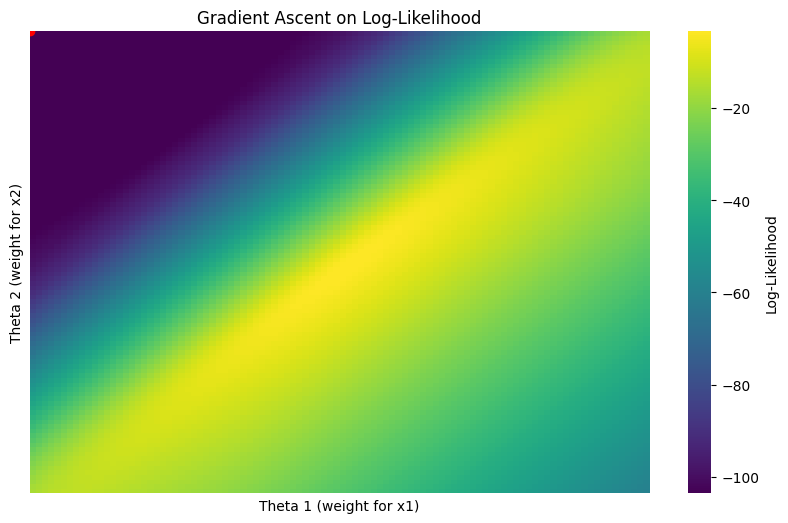

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.animation as animation

# Step 1: Generate synthetic binary classification data
np.random.seed(42)
X = np.array([
    [0.5, 1.5],
    [1.0, 1.0],
    [1.5, 0.5],
    [3.0, 3.5],
    [3.5, 3.0],
    [4.0, 4.0]
])
y = np.array([0, 0, 0, 1, 1, 1])

# Step 2: Add bias term to feature matrix
X_bias = np.hstack([np.ones((X.shape[0], 1)), X])

# Step 3: Define sigmoid and log-likelihood functions
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def log_likelihood(X, y, theta):
    z = X @ theta
    p = sigmoid(z)
    eps = 1e-15
    p = np.clip(p, eps, 1 - eps)
    return np.sum(y * np.log(p) + (1 - y) * np.log(1 - p))

# Step 4: Gradient of the log-likelihood
def gradient(X, y, theta):
    p = sigmoid(X @ theta)
    return X.T @ (y - p)

# Step 5: Run gradient ascent to maximize log-likelihood
theta = np.array([0.0, 0.0, 0.0])  # theta0 (bias), theta1, theta2
lr = 0.1
iterations = 50
theta_history = [theta.copy()]
ll_history = [log_likelihood(X_bias, y, theta)]

for _ in range(iterations):
    grad = gradient(X_bias, y, theta)
    theta += lr * grad
    theta_history.append(theta.copy())
    ll_history.append(log_likelihood(X_bias, y, theta))

theta_history = np.array(theta_history)
ll_history = np.array(ll_history)

# Step 6: Create log-likelihood surface for plotting
theta0_vals = np.linspace(-10, 10, 100)
theta1_vals = np.linspace(-10, 10, 100)
ll_vals = np.zeros((len(theta0_vals), len(theta1_vals)))
theta2_fixed = 0.0  # fix bias term for 2D visualization

for i, t0 in enumerate(theta0_vals):
    for j, t1 in enumerate(theta1_vals):
        theta_tmp = np.array([theta2_fixed, t0, t1])
        ll_vals[j, i] = log_likelihood(X_bias, y, theta_tmp)

# Step 7: Create animation
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(ll_vals, cmap='viridis', xticklabels=False, yticklabels=False,
            cbar_kws={'label': 'Log-Likelihood'}, ax=ax)
scat = ax.plot([], [], 'ro-', lw=2)[0]
ax.set_title("Gradient Ascent on Log-Likelihood")
ax.set_xlabel("Theta 1 (weight for x1)")
ax.set_ylabel("Theta 2 (weight for x2)")

def animate(i):
    scat.set_data(theta_history[:i+1, 1], theta_history[:i+1, 2])
    return scat,

ani = animation.FuncAnimation(fig, animate, frames=len(theta_history), interval=200, blit=True)
plt.show()

In [10]:
ani.save("gradient_ascent.gif", writer="pillow", fps=10)

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

# Generate synthetic binary classification data
np.random.seed(42)
X = np.array([
    [0.5, 1.5],
    [1.0, 1.0],
    [1.5, 0.5],
    [3.0, 3.5],
    [3.5, 3.0],
    [4.0, 4.0]
])
y = np.array([0, 0, 0, 1, 1, 1])

# Add bias term
X_bias = np.hstack([np.ones((X.shape[0], 1)), X])

# Sigmoid and log-likelihood
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def log_likelihood(X, y, theta):
    z = X @ theta
    p = sigmoid(z)
    eps = 1e-15
    p = np.clip(p, eps, 1 - eps)
    return np.sum(y * np.log(p) + (1 - y) * np.log(1 - p))

def gradient(X, y, theta):
    return X.T @ (y - sigmoid(X @ theta))

# Gradient ascent
theta = np.zeros(3)
lr = 0.1
iterations = 50
theta_history = [theta.copy()]
ll_history = [log_likelihood(X_bias, y, theta)]

for _ in range(iterations):
    grad = gradient(X_bias, y, theta)
    theta += lr * grad
    theta_history.append(theta.copy())
    ll_history.append(log_likelihood(X_bias, y, theta))

theta_history = np.array(theta_history)
ll_history = np.array(ll_history)

# Setup the plot
fig, ax = plt.subplots(figsize=(8, 6))

colors = ['blue' if label == 0 else 'red' for label in y]
scatter = ax.scatter(X[:, 0], X[:, 1], c=colors, edgecolors='k', s=100)
line, = ax.plot([], [], 'k--', linewidth=2)

ax.set_xlim(0, 5)
ax.set_ylim(0, 5)
ax.set_title("Logistic Regression: Decision Boundary via Gradient Ascent", fontsize=14)
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")

def animate(i):
    theta = theta_history[i]
    x_vals = np.array([0, 5])
    if theta[2] != 0:
        y_vals = -(theta[0] + theta[1] * x_vals) / theta[2]
    else:
        y_vals = np.array([0, 0])
    line.set_data(x_vals, y_vals)
    return line,

ani = animation.FuncAnimation(fig, animate, frames=len(theta_history), interval=200, blit=True)
plt.close(fig)
HTML(ani.to_jshtml())

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from sklearn.datasets import make_classification
from IPython.display import HTML

# Step 1: Generate synthetic classification data
X, y = make_classification(
    n_samples=1000, n_features=2, n_redundant=0, 
    n_clusters_per_class=1, flip_y=0.01, class_sep=10, random_state=42
)

# Step 2: Add bias term
X_bias = np.hstack([np.ones((X.shape[0], 1)), X])

# Step 3: Define sigmoid, log-likelihood, and gradient
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def log_likelihood(X, y, theta):
    z = X @ theta
    p = sigmoid(z)
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return np.sum(y * np.log(p) + (1 - y) * np.log(1 - p))

def gradient(X, y, theta):
    return X.T @ (y - sigmoid(X @ theta))

# Step 4: Gradient ascent to maximize log-likelihood
theta = np.zeros(3)
lr = 0.01
theta_history = [theta.copy()]

for _ in range(100):
    theta += lr * gradient(X_bias, y, theta)
    theta_history.append(theta.copy())

theta_history = np.array(theta_history)

# Step 5: Setup plot
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['blue' if label == 0 else 'red' for label in y]
ax.scatter(X[:, 0], X[:, 1], c=colors, edgecolors='k', s=40, alpha=0.6)
line, = ax.plot([], [], 'k--', linewidth=2)

ax.set_xlim(X[:, 0].min()-1, X[:, 0].max()+1)
ax.set_ylim(X[:, 1].min()-1, X[:, 1].max()+1)
ax.set_title("Logistic Regression via Gradient Ascent (Animated)", fontsize=14)
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")

# Step 6: Animate decision boundary
def animate(i):
    theta = theta_history[i]
    x_vals = np.array([X[:, 0].min()-1, X[:, 0].max()+1])
    if theta[2] != 0:
        y_vals = -(theta[0] + theta[1]*x_vals) / theta[2]
    else:
        y_vals = np.array([0, 0])
    line.set_data(x_vals, y_vals)
    return line,

ani = animation.FuncAnimation(fig, animate, frames=len(theta_history), interval=100, blit=True)
plt.close()
HTML(ani.to_jshtml())

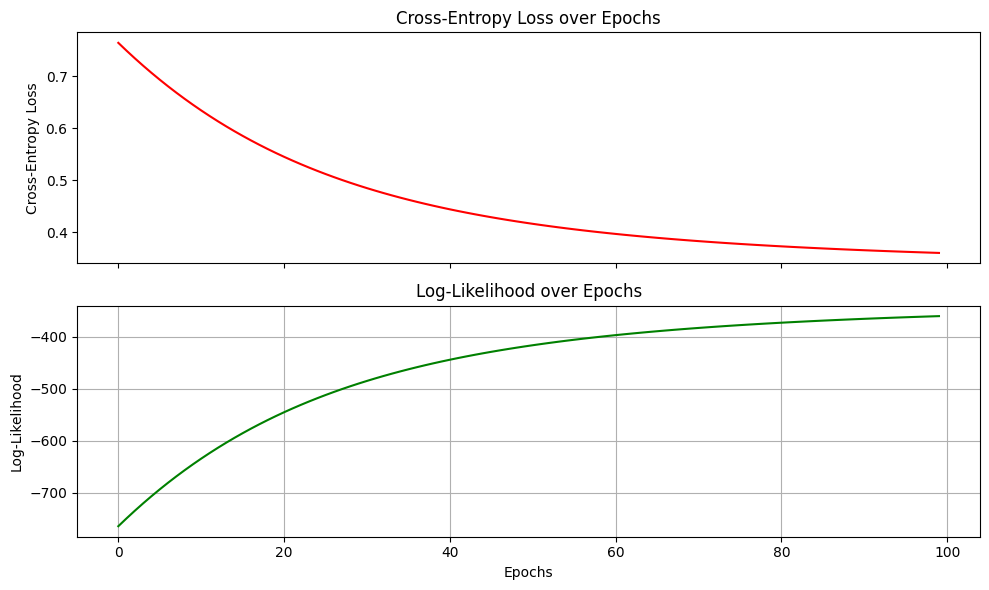

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from matplotlib.animation import FuncAnimation

# Sigmoid and Loss Functions
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def binary_cross_entropy(y_true, y_pred):
    y_pred = np.clip(y_pred, 1e-15, 1 - 1e-15)  # avoid log(0)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

def log_likelihood(y_true, y_pred):
    y_pred = np.clip(y_pred, 1e-15, 1 - 1e-15)
    return np.sum(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

# Generate synthetic data
X, y = make_classification(n_samples=1000, n_features=2, n_redundant=0, 
                           n_informative=2, random_state=42)
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Add bias term
X = np.hstack([np.ones((X.shape[0], 1)), X])  # Shape: (1000, 3)

# Initialize weights
np.random.seed(0)
weights = np.random.randn(X.shape[1])
lr = 0.1
n_epochs = 100

# Track losses
ce_losses = []
ll_vals = []
weights_history = []

# Training loop
for epoch in range(n_epochs):
    z = X @ weights
    preds = sigmoid(z)
    
    # Compute losses
    ce_loss = binary_cross_entropy(y, preds)
    ll = log_likelihood(y, preds)
    
    ce_losses.append(ce_loss)
    ll_vals.append(ll)
    weights_history.append(weights.copy())
    
    # Gradient descent
    gradient = X.T @ (preds - y) / len(y)
    weights -= lr * gradient

# Plotting CE vs Log-Likelihood
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax[0].plot(range(n_epochs), ce_losses, color='red')
ax[0].set_ylabel("Cross-Entropy Loss")
ax[0].set_title("Cross-Entropy Loss over Epochs")

ax[1].plot(range(n_epochs), ll_vals, color='green')
ax[1].set_ylabel("Log-Likelihood")
ax[1].set_title("Log-Likelihood over Epochs")
ax[1].set_xlabel("Epochs")

plt.tight_layout()
plt.grid(True)
plt.show()